# Quarterly inflation — AR mean and cautious GARCH with makystats

**Series.** Quarterly inflation `Dp` from the shipped `interest_inflation.csv` (same file as the inflation ARMA example), ~1972–1998.

**Why this example?** At **quarterly** frequency, **mean dynamics** (seasonal AR structure) dominate. Volatility clustering is weaker and the sample is **short** (\(T \approx 100\)), so GARCH must be introduced carefully — another honest use of makystats: joint estimation + IC, without overselling variance models on small \(T\).

**Links.** [PyPI](https://pypi.org/project/makystats/) · [Docs](https://lauret-boris.github.io/makystats/) · [GitHub](https://github.com/Lauret-Boris/makystats)


## 1. Setup


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from makystats import arma_garch, select_order
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (11, 4.0)

## 2. Data


In [2]:
path = "data/interest_inflation.csv"
raw = pd.read_csv(path)
# quarterly PeriodIndex
idx = pd.PeriodIndex.from_fields(
    year=raw["year"].astype(int), quarter=raw["quarter"].astype(int), freq="Q"
)
y = pd.Series(raw["Dp"].astype(float).values, index=idx, name="Dp")
print(path, len(y), y.index[0], "→", y.index[-1])
y.describe().round(4)

data/interest_inflation.csv 107 1972Q2 → 1998Q4


count    107.0000
mean       0.0084
std        0.0189
min       -0.0292
25%       -0.0043
50%        0.0087
75%        0.0239
max        0.0430
Name: Dp, dtype: float64

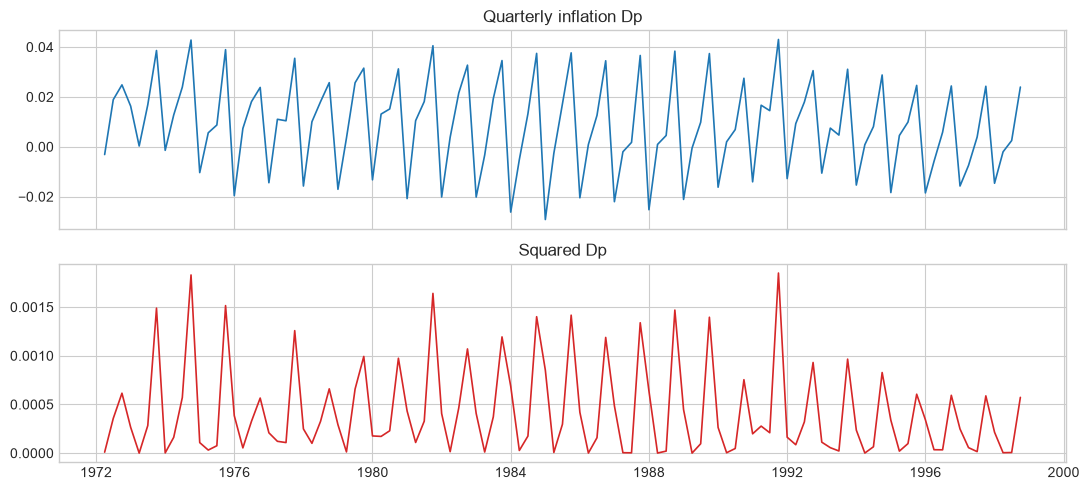

Ljung–Box levels


,lb_stat,lb_pvalue
4,120.1698,0.0
8,235.8725,0.0


Ljung–Box squares


,lb_stat,lb_pvalue
4,123.3678,0.0
8,237.5229,0.0


In [3]:
fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
axes[0].plot(y.to_timestamp(), lw=1.2)
axes[0].set_title("Quarterly inflation Dp")
axes[1].plot((y**2).to_timestamp(), lw=1.2, color="C3")
axes[1].set_title("Squared Dp")
fig.tight_layout()
plt.show()

def lb(s, title):
    d = acorr_ljungbox(np.asarray(s, float), lags=[4, 8], return_df=True)
    print(title); display(d.round(4))
lb(y - y.mean(), "Ljung–Box levels")
lb((y - y.mean())**2, "Ljung–Box squares")

**Reading.** Strong **seasonal** level dependence (lag 4). Squares may also be dependent, but with \(T \approx 100\) a rich GARCH is easy to overfit.


## 3. Step A — Mean only (no GARCH)

Economic / time-series prior for quarterly inflation: **AR with seasonal lag 4** (as in the pure ARMA inflation notebook), not a daily-style GARCH-first story.


In [4]:
def report(name, res):
    print("=== %s ===" % name)
    print("LogL=%.2f  AIC=%.2f  BIC=%.2f" % (res.loglik, res.aic, res.bic))
    print("LB resid p=%.4g | LB resid2 p=%.4g" % (res.ljungbox_resid_pval, res.ljungbox_resid2_pval))
    display(res.coef_table.round(4))

res_A = arma_garch(
    y, mean="AR", ar=4, ma=0, r=0, s=0, dist="normal", trend="c"
).fit(verbose=False)
res_A.summary()


   ARMA(4,0) - GARCH(0,0) — MLE (MLE)
   Mean: AR  |  trend=c  |  Distribution: NORMAL  |  Optimiseur: BFGS non contraint (reparam.)
   Backcast exponentiel: lambda = 0.7  |  Cov: OPG
Log-Likelihood : 374.880476
AIC            : -737.7610
BIC            : -721.9526
Sample (adjusted) : 5 107  (burn-in = 4)
Observations   : 103
Paramètres     : 6

--- Coefficients (IC 95% dans self.coef_table) ---
          Coeff   Std.Err     z-Stat     Prob.  CI_low_95  CI_high_95
const  0.006917  0.002915   2.373144  0.017637   0.001204    0.012630
AR(1) -0.071623  0.047555  -1.506101  0.132041  -0.164830    0.021584
AR(2) -0.063874  0.052038  -1.227448  0.219654  -0.165867    0.038119
AR(3) -0.061299  0.048883  -1.253991  0.209845  -0.157108    0.034510
AR(4)  0.891587  0.050010  17.828242  0.000000   0.793569    0.989604
omega  0.000040  0.000006   7.019246  0.000000   0.000029    0.000052

--- Diagnostic ---
alpha+beta = 0.000000
Ljung-Box (10) sur résidus std : p-val = 0.3489
Ljung-Box (10) sur c

**Diagnosis A.** AR(4) captures the seasonal peak (lag-4 coefficient). Check whether residual **squares** still demand GARCH.


## 4. Step B — AR(4)–GARCH(1,1)


In [5]:
res_B = arma_garch(
    y, mean="AR", ar=4, ma=0, vol="GARCH", r=1, s=1, dist="normal", trend="c"
).fit(verbose=False)
report("B — AR(4)–GARCH(1,1)", res_B)

# low-order ARMA + GARCH for comparison (not seasonal)
res_B2 = arma_garch(
    y, mean="ARMA", ar=1, ma=1, vol="GARCH", r=1, s=1, dist="normal", trend="c"
).fit(verbose=False)
report("B2 — ARMA(1,1)–GARCH(1,1) (misses seasonal lag 4)", res_B2)

comp = pd.DataFrame({
    "AR(4) const var": [res_A.aic, res_A.bic, res_A.ljungbox_resid_pval, res_A.ljungbox_resid2_pval],
    "AR(4)–GARCH": [res_B.aic, res_B.bic, res_B.ljungbox_resid_pval, res_B.ljungbox_resid2_pval],
    "ARMA(1,1)–GARCH": [res_B2.aic, res_B2.bic, res_B2.ljungbox_resid_pval, res_B2.ljungbox_resid2_pval],
}, index=["AIC", "BIC", "LB_resid_p", "LB_resid2_p"])
display(comp.round(4))

=== B — AR(4)–GARCH(1,1) ===
LogL=380.81  AIC=-745.61  BIC=-724.54
LB resid p=0.3805 | LB resid2 p=0.4812


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0053,0.0024,2.1729,0.0298,0.0005,0.0100
AR(1),-0.0605,0.0474,-1.2755,0.2021,-0.1534,0.0324
AR(2),-0.0595,0.0549,-1.0839,0.2784,-0.1671,0.0481
AR(3),-0.0813,0.0534,-1.5229,0.1278,-0.1859,0.0233
AR(4),0.8981,0.0478,18.8090,0.0000,0.8045,0.9917
omega,0.0000,0.0000,1.2019,0.2294,-0.0000,0.0000
alpha(1),0.0937,0.0638,1.4688,0.1419,-0.0313,0.2188
beta(1),0.8215,0.1022,8.0412,0.0000,0.6212,1.0217


=== B2 — ARMA(1,1)–GARCH(1,1) (misses seasonal lag 4) ===
LogL=277.22  AIC=-542.43  BIC=-526.45
LB resid p=1.21e-44 | LB resid2 p=6.093e-46


,Coeff,Std.Err,z-Stat,Prob.,CI_low_95,CI_high_95
const,0.0076,0.0006,13.4108,0.0000,0.0065,0.0087
AR(1),0.8542,0.0575,14.8609,0.0000,0.7415,0.9668
MA(1),-0.9815,0.0180,-54.4413,0.0000,-1.0169,-0.9462
omega,0.0000,0.0000,0.7165,0.4737,-0.0001,0.0001
alpha(1),-0.0253,0.0910,-0.2784,0.7807,-0.2038,0.1531
beta(1),0.9278,0.1943,4.7764,0.0000,0.5471,1.3086


,AR(4) const var,AR(4)–GARCH,"ARMA(1,1)–GARCH"
AIC,-737.7610,-745.6139,-542.4319
BIC,-721.9526,-724.5361,-526.4512
LB_resid_p,0.3489,0.3805,0.0000
LB_resid2_p,0.0003,0.4812,0.0000


**Diagnosis B.**
- **AR(4)** mean dominates ARMA(1,1): seasonal structure is not a daily ARMA(1,1).
- GARCH may improve residual squares **or** look fragile (insignificant \(\alpha\), short \(T\)). Report IC **and** coefficient significance — do not claim a strong volatility story if \(\alpha\) is weak.


## 5. Why not a large `select_order` here?

Quarterly inflation needs **lag 4** (seasonal). A default `p_range=range(0, 3)` **never sees** AR(4). Options:

1. **Theory-first:** fix AR(4), compare variance specs by hand (done above) — preferred on short T.
2. **Targeted grid:** `p_range=[1, 2, 4]` with `mean="AR"`, `q_range=[0]`, GARCH(1,1) only — still uses makystats `select_order` without a kitchen-sink search.

Below: targeted grid + explicit constant-variance AR(4) already computed.


In [6]:
# Targeted select_order: seasonal lag 4 is *in* the p grid on purpose
table, best = select_order(
    y,
    p_range=[1, 2, 4],
    q_range=[0],
    r_range=[1],
    s_range=[1],
    dist=["normal"],
    variance_model=["garch"],
    criterion="bic",
    mean="AR",
    trend="c",
    verbose=False,
    n_jobs=1,
    return_best=True,
)
display(table[["aic", "bic", "ok"]].sort_values("bic"))
print("Best among AR(p)–GARCH(1,1):", table.attrs.get("best"))

# Still compare to AR(4) without GARCH (not in the GARCH-only grid)
rows = [
    {"model": "AR(4) const var", "AIC": res_A.aic, "BIC": res_A.bic},
    {"model": "select_order best (GARCH)", "AIC": best.aic, "BIC": best.bic},
]
display(pd.DataFrame(rows).set_index("model").round(2))

,aic,bic,ok
label,,,
"ARMA(4,0)-garch(1,1)-normal",-745.613901,-724.536069,True
"ARMA(2,0)-garch(1,1)-normal",-553.722904,-537.914530,True
"ARMA(1,0)-garch(1,1)-normal",-532.493553,-519.319908,True


Best among AR(p)–GARCH(1,1): ARMA(4,0)-garch(1,1)-normal


,AIC,BIC
model,,
AR(4) const var,-737.76,-721.95
select_order best (GARCH),-745.61,-724.54


## 6. Preferred narrative fit


Selected: AR(4)–GARCH hand BIC=-724.54


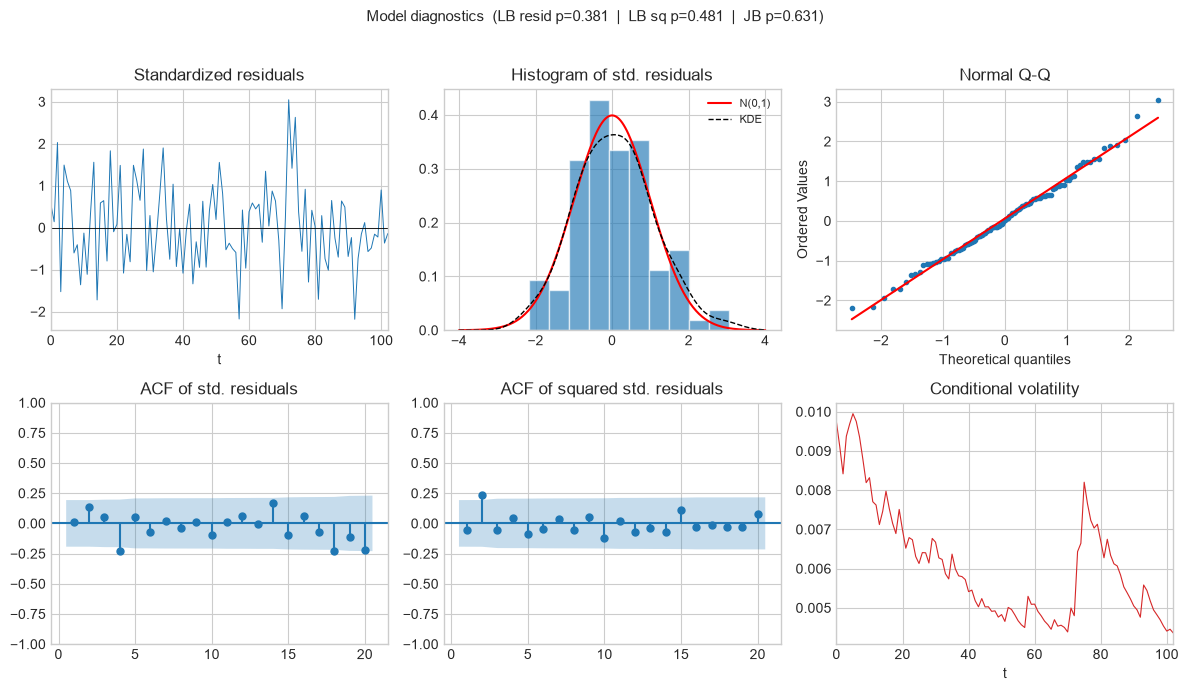

In [7]:
# Prefer lower BIC among: AR(4) const var, hand AR(4)–GARCH, select_order best
cands = {
    "AR(4) const var": res_A,
    "AR(4)–GARCH hand": res_B,
    "select_order best": best,
}
res = min(cands.values(), key=lambda r: r.bic)
label = [k for k, v in cands.items() if v is res][0]
print("Selected:", label, "BIC=%.2f" % res.bic)
try:
    fig = res.plot_diagnostics()
    plt.show()
except Exception as e:
    print("plot_diagnostics:", e)


## 7. Takeaways

1. **Frequency matters:** quarterly inflation → **seasonal AR** first; GARCH is secondary and sample-limited.
2. ARMA(1,1)–GARCH is the wrong mean template; **AR(4)** matches the seasonal lag.
3. **`select_order`** remains useful if the grid **includes** lag 4 — a reminder that the tool is only as good as the ranges you pass.
4. makystats: same API for mean-only and mean+GARCH, joint IC, residual tests.

Data: same `interest_inflation.csv` as the inflation ARMA example.
